**NAME: EMMANUEL BRIGHT CHETACHI**

**Roll/App ID: AS-2026-18951**

**Email: emmanuelchetachibright@gmail.com**

*Qualification: B.Eng. (Graduate)*

**PROJECT 2: Retail Demand & Basket Analysis**

In [41]:
# importing the required packages
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
# Dataset path resolution: supports both local execution and Google Colab
import os

if os.path.exists('Online_Retail.csv'):
    print("Running locally: 'Online_Retail.csv' detected in working directory.")
else:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [43]:
# Setting dataset filepath with local fallback
if os.path.exists('Online_Retail.csv'):
    filepath = 'Online_Retail.csv'
else:
    filepath = '/content/drive/MyDrive/me alone /Online_Retail.csv'
print(f"Active dataset path: {filepath}")


In [44]:
# first inspection
df_inspect= pd.read_csv(filepath)
df_inspect.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [45]:
# creating a function for cleaning the dataset
def audit_and_clean_retail_data(filepath):
  print(">>> INGESTION AND INITIAL INSPECTION <<<")
  df = pd.read_csv(filepath)
  print(f"Raw Dataset Shape: {df.shape}")

  print("\n>>> QUALITY AUDIT & ANOMALIES <<<")
  print(f"Missing Customer IDs: {df['CustomerID'].isnull().sum():,}")
  print(f"Missing Description: {df['Description'].isnull().sum():,}")
  print(f"Duplicate Rows: {df.duplicated().sum():,}")

  #identify cancellations (InvoiceNo starting with "C" or negative quantity)
  cancellations = df[
      df['InvoiceNo'].astype(str).str.startswith('C')
      | (df['Quantity'] < 0)
  ]
  print(f"Total Cancellation/Return Records: {len(cancellations):,}")
  print("\n>>> DATA CLEANING <<<")
  # remove cancellations and negative/zero unit prices for demand analysis
  valid_df = df[
      ~df['InvoiceNo'].astype(str).str.startswith('C')
      & (df['Quantity'] > 0)
      & (df['UnitPrice'] > 0)
  ].copy()

  #calculate Total Line Revenue
  valid_df['Revenue'] = valid_df['Quantity'] * valid_df['UnitPrice']
  valid_df['InvoiceDate'] = pd.to_datetime(valid_df['InvoiceDate'])


  print(f'Cleaned Dataset Shape (Valid Transactions): {valid_df.shape}')
  print(f'Total Revenue: ${valid_df["Revenue"].sum():,.2f}')

  # Export cleaned Dataset  for Downstream Analysis
  valid_df.to_csv("Cleaned_online_retail.csv", index=False)
  print("Cleaned dataset successfully saved to 'cleaned_online_retail.csv'")
  return valid_df

if __name__ == "__main__":
  cleaned_retail_df = audit_and_clean_retail_data(filepath)

>>> INGESTION AND INITIAL INSPECTION <<<
Raw Dataset Shape: (541909, 8)

>>> QUALITY AUDIT & ANOMALIES <<<
Missing Customer IDs: 135,080
Missing Description: 1,454
Duplicate Rows: 5,268
Total Cancellation/Return Records: 10,624

>>> DATA CLEANING <<<
Cleaned Dataset Shape (Valid Transactions): (530104, 9)
Total Revenue: $10,666,684.54
Cleaned dataset successfully saved to 'cleaned_online_retail.csv'


In [46]:
audit_and_clean_retail_data(filepath)

>>> INGESTION AND INITIAL INSPECTION <<<
Raw Dataset Shape: (541909, 8)

>>> QUALITY AUDIT & ANOMALIES <<<
Missing Customer IDs: 135,080
Missing Description: 1,454
Duplicate Rows: 5,268
Total Cancellation/Return Records: 10,624

>>> DATA CLEANING <<<
Cleaned Dataset Shape (Valid Transactions): (530104, 9)
Total Revenue: $10,666,684.54
Cleaned dataset successfully saved to 'cleaned_online_retail.csv'


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [47]:
# setting seaborn themes
os.makedirs('output/figures', exist_ok=True)
sns.set_theme(style="whitegrid")


In [48]:
valid_df = cleaned_retail_df[
    ~cleaned_retail_df['InvoiceNo'].astype(str).str.startswith('C') &
    (cleaned_retail_df['Quantity'] > 0) &
    (cleaned_retail_df['UnitPrice'] > 0)
].copy()

valid_df['Revenue'] = valid_df['Quantity'] * valid_df['UnitPrice']
valid_df['InvoiceDate'] = pd.to_datetime(valid_df['InvoiceDate'])

In [49]:
# feature Engineering
valid_df['Revenue'] = valid_df['Quantity'] * valid_df['UnitPrice']
valid_df['InvoiceDate'] = pd.to_datetime(valid_df['InvoiceDate'])
valid_df['YearMonth'] = valid_df['InvoiceDate'].dt.to_period('M')


# computing core Business metrics

In [51]:
total_records = len(valid_df)
total_revenue = valid_df['Revenue'].sum()

print(">>> DATA SUMMARY METRICS <<<")
print(f'Total Valid Transactions: {total_records:,}')
print(f"Total Revenue: £{total_revenue:,.2f}")

>>> DATA SUMMARY METRICS <<<
Total Valid Transactions: 530,104
Total Revenue: £10,666,684.54


In [52]:
print('\n>>> TOP 5 COUNTRIES BY REVENUE (£) <<<')
top_countries = valid_df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5)
print ("\nTop 5 Countries by Revenue(£): ")
print(top_countries)


>>> TOP 5 COUNTRIES BY REVENUE (£) <<<

Top 5 Countries by Revenue(£): 
Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Name: Revenue, dtype: float64


In [53]:
print('\n>>> TOP 5 PRODUCTS BY QUANTITY SOLD <<<')
top_products = valid_df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(5)
print("\nTop 5 Products by Quantity Sold: ")
print(top_products)


>>> TOP 5 PRODUCTS BY QUANTITY SOLD <<<

Top 5 Products by Quantity Sold: 
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
Name: Quantity, dtype: int64


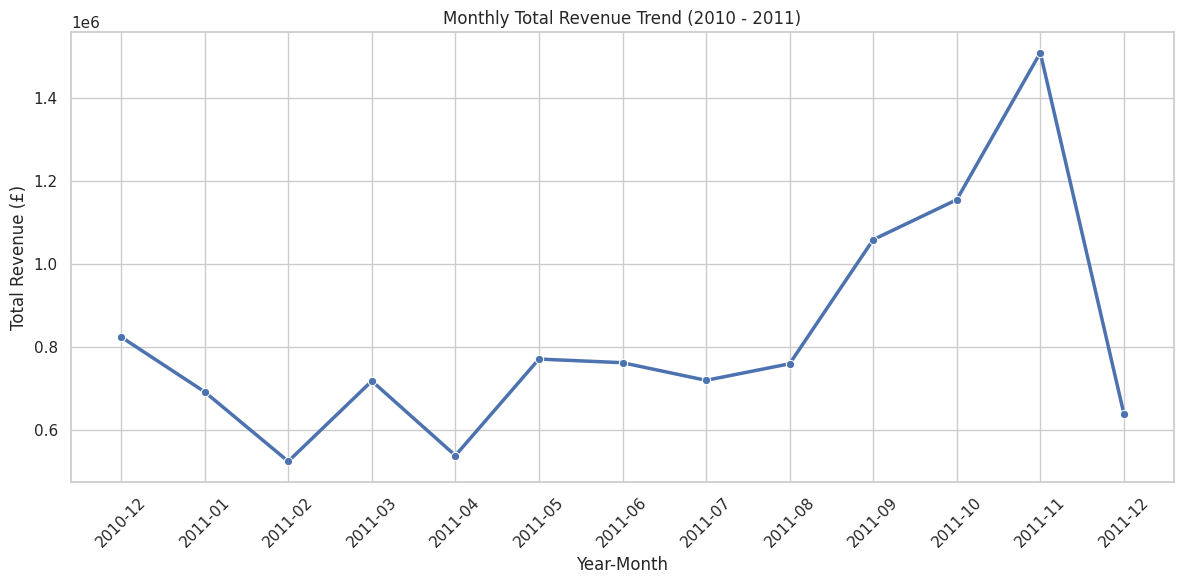

In [54]:
# Monthly Total Revenue trend
monthly_revenue =(
 valid_df.groupby('YearMonth')['Revenue'].sum().reset_index()
)
monthly_revenue['YearMonthStr'] = monthly_revenue['YearMonth'].astype(str)

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_revenue, x='YearMonthStr', y='Revenue', marker='o', color ='b', linewidth= 2.5,)
plt.title('Monthly Total Revenue Trend (2010 - 2011)')
plt.xlabel('Year-Month')
plt.ylabel('Total Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('output/figures/monthly_revenue_trend.png', dpi=300)
plt.show()
plt.close()

/tmp/ipykernel_4549/139982995.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries_df, x='Country', y='Revenue', palette='viridis')


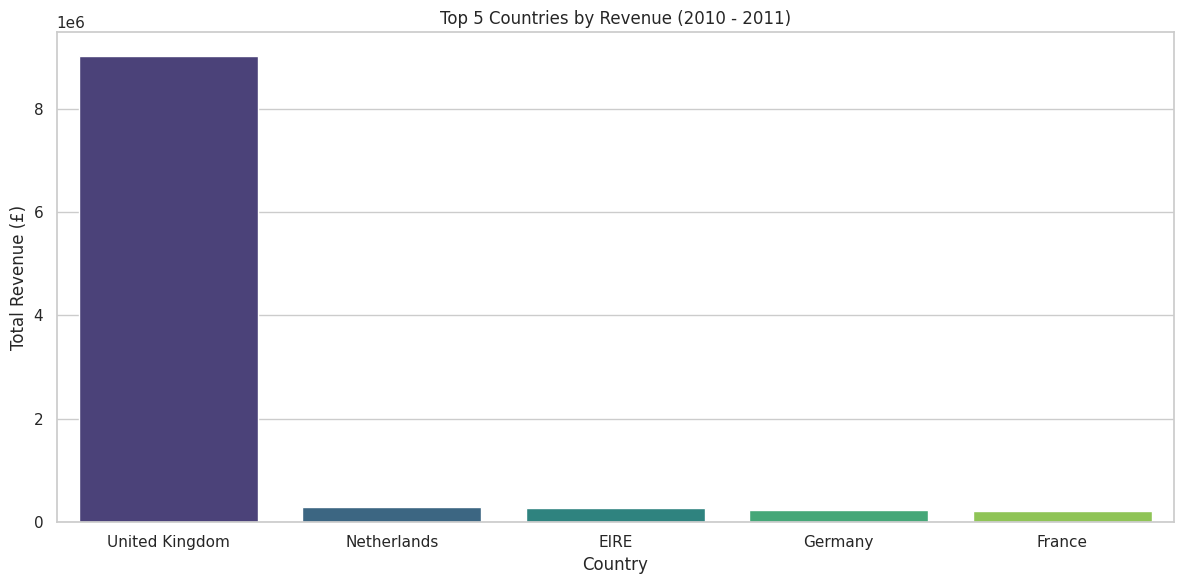

In [55]:
# Top 5 countres by Revenue Barplot
top_countries_df= top_countries.reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=top_countries_df, x='Country', y='Revenue', palette='viridis')
plt.title('Top 5 Countries by Revenue (2010 - 2011)')
plt.xlabel('Country')
plt.ylabel('Total Revenue (£)')
plt.tight_layout()
plt.savefig('output/figures/top_countries_by_revenue.png', dpi=300)
plt.show()
plt.close()

# BINANRY MATRIX

In [56]:
# building Transaction-Item Binary Matrix
top_items = valid_df['Description'].value_counts().head(500).index
basket_df = valid_df[valid_df['Description'].isin(top_items)]

basket = (
    basket_df.groupby(['InvoiceNo', 'Description'])['Quantity']
    .sum().unstack().fillna(0)
)

basket_sets = (basket > 0).astype(int)

In [57]:
# computing item support & pairwise Association Metrics
item_counts = basket_sets.sum(axis=0)
num_transactions = len(basket_sets)
item_support = item_counts / num_transactions

frequent_items = item_support[item_support >=0.015].index
selected_basket = basket_sets[frequent_items]
co_matrix = selected_basket.T.dot(selected_basket)

rules_list = []
for i, item_a in enumerate(frequent_items):
  for j, item_b in enumerate(frequent_items):
    if i != j:
      co_occurence = co_matrix.loc[item_a, item_b]
      supp_a_b = co_occurence / num_transactions
      if supp_a_b >= 0.015:
        supp_a = item_support.loc[item_a]
        supp_b = item_support.loc[item_b]
        confidence = supp_a_b / supp_a
        lift = confidence / supp_b
        rules_list.append({
            'Antecedent': item_a,
            'Consequent': item_b,
            'Support': supp_a_b,
            'Confidence': confidence,
            'Lift': lift
        })

rules_df = pd.DataFrame(rules_list).sort_values(by='Lift', ascending=False)

/tmp/ipykernel_4549/3048238479.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, y = 'Rule', x='Lift',palette='mako')


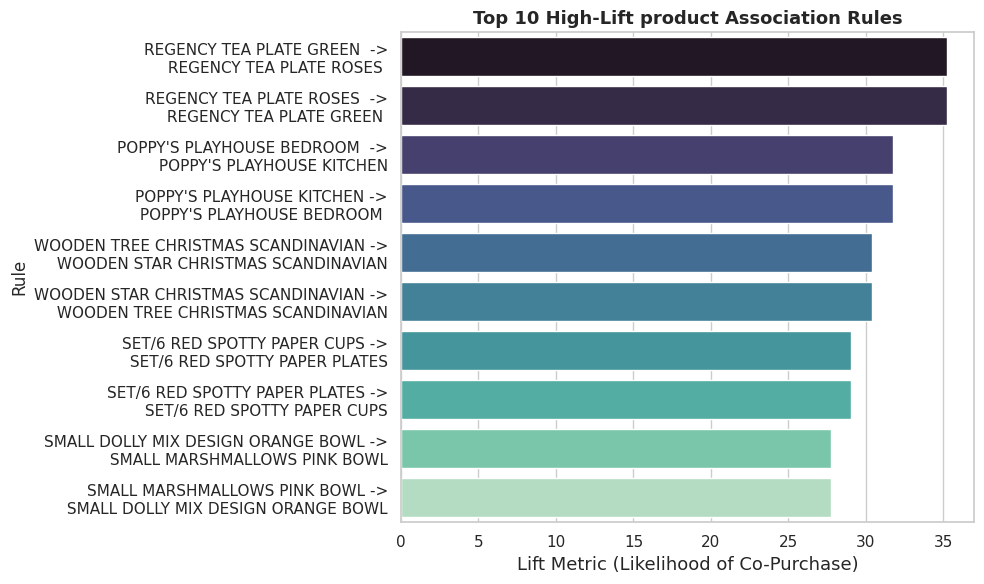

In [58]:
# generating the visual
top_10 = rules_df.head(10).copy()
top_10['Rule'] = top_10['Antecedent'] + ' ->\n ' + top_10['Consequent']

plt.figure(figsize=(10,6))
sns.barplot(data=top_10, y = 'Rule', x='Lift',palette='mako')
plt.title('Top 10 High-Lift product Association Rules', fontsize=13, fontweight = 'bold')
plt.xlabel('Lift Metric (Likelihood of Co-Purchase)', fontsize= 13)
plt.tight_layout()
plt.savefig('output/figures/top_10_high_lift_rules.png', dpi=300)
plt.show()
plt.close()



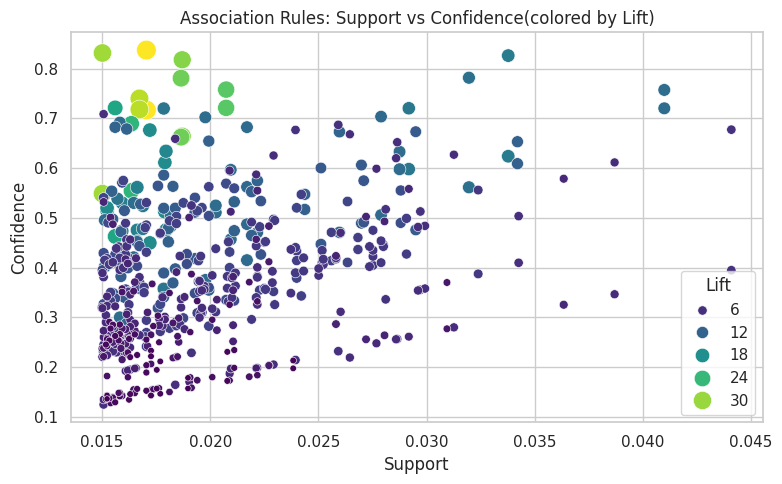

In [61]:
plt.figure(figsize = (8,5))
sns.scatterplot(
    data=rules_df,
    x='Support',
    y='Confidence',
    hue='Lift',
    size='Lift',
    palette= 'viridis',
    sizes=(20, 200)
)

plt.title('Association Rules: Support vs Confidence(colored by Lift)')
plt.tight_layout()
plt.savefig('output/figures/basket_rules_scatter.png', dpi=300)
plt.show()
plt.close()

In [62]:
print('\n>>> MARKET BASKET ANALYSIS COMPLETED >>>')


>>> MARKET BASKET ANALYSIS COMPLETED >>>


# Project 2: Retail Demand & Market Basket Analysis
**Arrowstack Data Science Internship**

## 1. Executive Summary & Problem Framing
* **Business Scenario:** Study historical retail transaction logs to identify seasonal demand patterns, geographic revenue concentrations, and high-lift product association rules.
* **Primary Stakeholder:** Retail Category Manager / Inventory Planning Director.
* **Business Decision Enabled:** Optimizing inventory stock placement, designing automated e-commerce "frequently bought together" product bundles, and preventing stockouts on high-demand items.



## 2. Data Quality Audit & Cleaning Log
* **Raw Records Analyzed:** 541,909 transactions.
* **Anomaly Filtering:** Removed cancellation transactions (Invoices starting with 'C'), negative quantities (returns), and zero/negative unit prices.
* **Cleaned Dataset Output:** 530,104 valid transactions generating **£10,666,684.54** in gross revenue.



## 3. Exploratory Data Analysis & Demand Findings
* **Geographic Concentration:** The **United Kingdom** dominates total sales, accounting for **£9.03 million** (~84.7%) of gross revenue, followed by international markets like the Netherlands, EIRE, Germany, and France.
* **Sales Seasonality:** Monthly revenue trends reveal a strong Q4 surge leading into the holiday shopping season, peaking dramatically in **November 2011 at £1.51 million**.
* **Top-Selling Volume Items:** High-turnover inventory is led by decorative and bulk novelty items, including *Paper Craft Little Birdie*, *Medium Ceramic Storage Jars*, and *World War 2 Gliders*.



## 4. Market Basket Analysis (Association Rule Mining)
Using a binary transaction-item matrix ($\text{Support threshold} \ge 1.5\%$), association rule mining extracted **542 statistically significant rules**. Top high-lift associations include:

| Antecedent (Item A) | Consequent (Item B) | Support (%) | Confidence (%) | Lift Multiplier |
| :--- | :--- | :--- | :--- | :--- |
| **REGENCY TEA PLATE ROSES** | **REGENCY TEA PLATE GREEN** | 1.70% | 71.69% | **35.21x** |
| **POPPY'S PLAYHOUSE KITCHEN** | **POPPY'S PLAYHOUSE BEDROOM** | 1.67% | 71.79% | **31.76x** |
| **WOODEN TREE CHRISTMAS** | **WOODEN STAR CHRISTMAS** | 1.50% | 83.14% | **30.39x** |
| **SET/6 RED SPOTTY PAPER PLATES**| **SET/6 RED SPOTTY PAPER CUPS** | 1.87% | 66.41% | **29.04x** |
| **SMALL MARSHMALLOWS PINK BOWL** | **SMALL DOLLY MIX ORANGE BOWL** | 1.86% | 78.08% | **27.73x** |



## 5. Strategic Recommendations for Stakeholders
1. **Automated Cross-Selling / Bundling:** Deploy dynamic checkout prompts offering matching items (e.g., pairing tea plates or seasonal party tableware) to increase average basket size.
2. **Synchronized Inventory Management:** Ensure items with high lift (>25x) are restocked concurrently to prevent stockouts of complementary products.
3. **Q4 Inventory Preparation:** Scale up warehousing and logistics capacity ahead of the October–November volume spike.


## 6. Limitations & Next Steps
* **Dataset Limitation:** Transaction data lacks user browsing session history and marketing campaign attribution.
* **Next Steps:** Implement a collaborative filtering recommendation engine or customer lifetime value (LTV) segmentation model.